# 🧠 Treinamento e Avaliação da Rede MLP (Classificação Celular Fujita 600D)

Este notebook implementa o pipeline de treinamento supervisionado para classificação de tipos celulares transcriptômicos a partir dos vetores espectrais **rSWeeP 600D** gerados no notebook `vetorizar.ipynb`.

### 📐 Especificações Experimentais:
- **Entrada:** $26.763$ células $\times 600$ dimensões espectrais (dados binarizados de expressão);
- **Particionamento Estratificado Rigoroso:** 70% Treino ($18.734$ células), 15% Validação ($4.014$ células) e 15% Teste ($4.015$ células);
- **Normalização:** `StandardScaler` ajustado estritamente no conjunto de treino (*zero data leakage*);
- **Topologia da Rede (Keras Sequential):**
  $$\text{Input}(600) \longrightarrow \text{Dense}(128, \text{ReLU}) \longrightarrow \text{Dense}(64, \text{ReLU}) \longrightarrow \text{Dense}(32, \text{ReLU}) \longrightarrow \text{Dense}(7, \text{Softmax})$$
- **Otimização:** `Adam`, perda `sparse_categorical_crossentropy`, $50$ épocas e `batch_size = 64`;
- **Visualizações:** Curvas de perda/acurácia e Matriz de Confusão geradas com **Plotly** (interativo) e **Seaborn** (estilizado para publicação);
- **Artefatos Gerados:** `modelo_mlp_fujita_600d.keras` e `scaler_fujita_600d.pkl`.


## ⚙️ Configuração e Importação de Pacotes


In [1]:
import os
import json
import time
from pathlib import Path

import numpy as np
import joblib
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Bibliotecas Gráficas Modernas
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Configuração de Reprodutibilidade Estatística
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Estilo Visual do Seaborn
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]

# Definição dos Caminhos de Dados e Artefatos
PATH_X = Path("dados/X_fujita_600d.npy")
PATH_Y = Path("dados/y_fujita.npy")
PATH_METADATA = Path("dados/metadata_classes.json")

PATH_MODELO_OUT = Path("modelo_mlp_fujita_600d.keras")
PATH_SCALER_OUT = Path("scaler_fujita_600d.pkl")

print("✓ Ambiente configurado e dependências importadas com sucesso!")
print(f"  • Versão do TensorFlow : {tf.__version__}")
print(f"  • Versão do Keras      : {tf.keras.__version__}")
print(f"  • Semente Fixada       : {SEED}")


2026-10-22 17:27:29.559130: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 17:27:29.782683: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-10-22 17:27:31.289973: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


✓ Ambiente configurado e dependências importadas com sucesso!
  • Versão do TensorFlow : 2.20.0
  • Versão do Keras      : 3.15.1
  • Semente Fixada       : 42


## 📂 Etapa 1: Carregamento dos Dados Vetorizados e Metadados

Carregamos a matriz de features $X$ e o vetor de rótulos $y$ produzidos pelo pipeline SWeeP, além do dicionário de mapeamento de classes.


In [2]:
t0 = time.time()

assert PATH_X.exists(), f"Erro: {PATH_X} não encontrado. Execute o vetorizar.ipynb primeiro!"
assert PATH_Y.exists(), f"Erro: {PATH_Y} não encontrado."

X = np.load(PATH_X)
y = np.load(PATH_Y)

with open(PATH_METADATA, "r", encoding="utf-8") as f:
    metadados = json.load(f)

nomes_classes_originais = [f"Classe {i+1}" for i in range(7)]

print(f"✓ Dados carregados em {time.time() - t0:.2f}s")
print(f"  • Matriz de Features X : {X.shape} (Dtype: {X.dtype})")
print(f"  • Vetor de Rótulos y   : {y.shape} (Dtype: {y.dtype})")
print(f"  • Intervalo de Classes : {y.min()} até {y.max()} (Total: {len(np.unique(y))} classes)")
print(f"  • NaNs detectados em X : {np.isnan(X).sum()}")

# Tabela de distribuição de amostras
print("\n  • Frequência de células por classe:")
for i in range(7):
    count = int((y == i).sum())
    pct = (count / len(y)) * 100
    print(f"    - Classe Keras {i} ({nomes_classes_originais[i]}): {count:>5,} células ({pct:>5.2f}%)")


✓ Dados carregados em 0.01s
  • Matriz de Features X : (26763, 600) (Dtype: float32)
  • Vetor de Rótulos y   : (26763,) (Dtype: int64)
  • Intervalo de Classes : 0 até 6 (Total: 7 classes)
  • NaNs detectados em X : 0

  • Frequência de células por classe:
    - Classe Keras 0 (Classe 1): 4,366 células (16.31%)
    - Classe Keras 1 (Classe 2):   188 células ( 0.70%)
    - Classe Keras 2 (Classe 3): 9,073 células (33.90%)
    - Classe Keras 3 (Classe 4): 4,567 células (17.06%)
    - Classe Keras 4 (Classe 5): 1,734 células ( 6.48%)
    - Classe Keras 5 (Classe 6): 5,762 células (21.53%)
    - Classe Keras 6 (Classe 7): 1,073 células ( 4.01%)


## ✂️ Etapa 2: Particionamento Estratificado (70% Treino / 15% Validação / 15% Teste)

Para garantir que classes com baixa representação (ex: Classe 2 original com 188 células) estejam proporcionalmente distribuídas em todos os conjuntos, aplicamos estratificação em duas etapas consecutivas:
1. **Separação de Teste:** $15\%$ do dataset reservado para teste final;
2. **Separação de Validação:** Dos $85\%$ restantes, separamos $15/85 \approx 17.65\%$, resultando em exatamente $15\%$ do total para validação e $70\%$ para treino.


In [3]:
# 1ª Etapa: Separação de 15% para Teste
X_treino_val, X_teste, y_treino_val, y_teste = train_test_split(
    X, y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

# 2ª Etapa: Separação dos 85% restantes em Treino (70% do total) e Validação (15% do total)
razao_validacao = 0.15 / (1.0 - 0.15)  # 15 / 85 ≈ 0.17647
X_treino, X_val, y_treino, y_val = train_test_split(
    X_treino_val, y_treino_val,
    test_size=razao_validacao,
    random_state=SEED,
    stratify=y_treino_val
)

total_amostras = len(y)
print("✓ Particionamento estratificado concluído com sucesso:")
print(f"  • Treino    : {X_treino.shape[0]:>6,} amostras ({X_treino.shape[0] / total_amostras * 100:.2f}%)")
print(f"  • Validação : {X_val.shape[0]:>6,} amostras ({X_val.shape[0] / total_amostras * 100:.2f}%)")
print(f"  • Teste     : {X_teste.shape[0]:>6,} amostras ({X_teste.shape[0] / total_amostras * 100:.2f}%)")
print(f"  • Total     : {total_amostras:>6,} amostras (100.00%)")


✓ Particionamento estratificado concluído com sucesso:
  • Treino    : 18,733 amostras (70.00%)
  • Validação :  4,015 amostras (15.00%)
  • Teste     :  4,015 amostras (15.00%)
  • Total     : 26,763 amostras (100.00%)


## ⚖️ Etapa 3: Normalização com `StandardScaler` (Zero Data Leakage)

Ajustamos a média ($\mu$) e desvio padrão ($\sigma$) do `StandardScaler` **exclusivamente sobre o conjunto de treino** (`fit_transform`). Os conjuntos de validação e teste são apenas transformados com os parâmetros aprendidos no treino (`transform`), prevenindo qualquer contaminação estatística (*data leakage*).


In [4]:
t_norm = time.time()
scaler = StandardScaler()

# Ajuste e transformação exclusivos no treino
X_treino_norm = scaler.fit_transform(X_treino)

# Apenas transformação nos dados de validação e teste
X_val_norm = scaler.transform(X_val)
X_teste_norm = scaler.transform(X_teste)

print(f"✓ Normalização concluída em {time.time() - t_norm:.2f}s!")
print(f"  • Média de Treino normalizado : {X_treino_norm.mean():.4f} (esperado ≈ 0)")
print(f"  • Desvio Padrão de Treino     : {X_treino_norm.std():.4f} (esperado ≈ 1)")
print(f"  • Média de Validação          : {X_val_norm.mean():.4f}")
print(f"  • Média de Teste              : {X_teste_norm.mean():.4f}")


✓ Normalização concluída em 0.11s!
  • Média de Treino normalizado : 0.0000 (esperado ≈ 0)


  • Desvio Padrão de Treino     : 1.0000 (esperado ≈ 1)
  • Média de Validação          : -0.0014
  • Média de Teste              : 0.0005


## 🏗️ Etapa 4: Construção e Compilação da Arquitetura MLP

Definimos o modelo sequencial no Keras conforme a topologia solicitada:
- **Camada 1:** `Dense(128, activation='relu', input_shape=(600,))`
- **Camada 2:** `Dense(64, activation='relu')`
- **Camada 3:** `Dense(32, activation='relu')`
- **Camada de Saída:** `Dense(7, activation='softmax')`
- **Otimizador:** `Adam` | **Perda:** `sparse_categorical_crossentropy` | **Métrica:** `accuracy`


In [5]:
modelo = Sequential([
    Dense(128, activation='relu', input_shape=(600,), name="densa_128"),
    Dense(64, activation='relu', name="densa_64"),
    Dense(32, activation='relu', name="densa_32"),
    Dense(7, activation='softmax', name="saida_softmax_7")
], name="MLP_Classificador_Celular_Fujita")

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

modelo.summary()


/home/rasert/workspace/Teste_MlP_fujita_para_fujitafaltante_fujitapos_imputacao/.venv/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1792700853.006968  847036 cuda_executor.cc:1309] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792700853.013860  847036 gpu_device.cc:2342] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU dev

Model: "MLP_Classificador_Celular_Fujita"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densa_128 (Dense)               │ (None, 128)            │        76,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida_softmax_7 (Dense)         │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,495 (341.78 KB)

 Trainable params: 87,495 (341.78 KB)

 Non-trainable params: 0 (0.00 B)

## 🏋️ Etapa 5: Treinamento do Modelo (50 Épocas, Batch Size = 64)

Treinamos o modelo utilizando os $18.734$ exemplos do conjunto de treino normalizado e avaliamos o desempenho a cada época contra o conjunto de validação explícito ($4.014$ exemplos).


In [6]:
t_treino = time.time()
EPOCHS = 50
BATCH_SIZE = 64

print(f"Iniciando treinamento por {EPOCHS} épocas com batch_size={BATCH_SIZE}...")

historico = modelo.fit(
    X_treino_norm,
    y_treino,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_norm, y_val),
    verbose=1
)

tempo_total_treino = time.time() - t_treino
print(f"\n✓ Treinamento concluído em {tempo_total_treino:.2f}s ({tempo_total_treino / 60:.2f} minutos)!")


Iniciando treinamento por 50 épocas com batch_size=64...


Epoch 1/50


  1/293 ━━━━━━━━━━━━━━━━━━━━ 4:38 953ms/step - accuracy: 0.2500 - loss: 1.9422

 27/293 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6464 - loss: 0.9889    

 54/293 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7902 - loss: 0.6300

...

233/293 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.9306e-08

261/293 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.9390e-08

288/293 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.9383e-08

293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 1.9377e-08 - val_accuracy: 0.9970 - val_loss: 0.0167



✓ Treinamento concluído em 35.00s (0.58 minutos)!


## 📈 Etapa 6: Visualização das Curvas de Aprendizado (Plotly & Seaborn)

Plotamos a evolução da acurácia e da perda ao longo das 50 épocas tanto em visualização interativa com **Plotly** quanto em gráfico refinado com **Seaborn**.


In [7]:
# Extração das séries históricas
epocas_range = list(range(1, EPOCHS + 1))
acc_treino = [float(v) for v in historico.history['accuracy']]
acc_val = [float(v) for v in historico.history['val_accuracy']]
loss_treino = [float(v) for v in historico.history['loss']]
loss_val = [float(v) for v in historico.history['val_loss']]

# =====================================================================
# 1. VISUALIZAÇÃO INTERATIVA EM PLOTLY (Hover, Zoom e Tooltips Dinâmicos)
# =====================================================================
fig_plotly = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Evolução da Acurácia (Treino vs. Validação)", "Evolução da Perda (Treino vs. Validação)"),
    horizontal_spacing=0.12
)

# Acurácia
fig_plotly.add_trace(
    go.Scatter(x=epocas_range, y=acc_treino, mode='lines+markers', name='Acurácia Treino',
               line=dict(color='#2b5c8f', width=2.5), marker=dict(size=4)),
    row=1, col=1
)
fig_plotly.add_trace(
    go.Scatter(x=epocas_range, y=acc_val, mode='lines+markers', name='Acurácia Validação',
               line=dict(color='#e26d5c', width=2.5, dash='dot'), marker=dict(size=4)),
    row=1, col=1
)

# Perda
fig_plotly.add_trace(
    go.Scatter(x=epocas_range, y=loss_treino, mode='lines+markers', name='Perda Treino',
               line=dict(color='#2b5c8f', width=2.5), marker=dict(size=4)),
    row=1, col=2
)
fig_plotly.add_trace(
    go.Scatter(x=epocas_range, y=loss_val, mode='lines+markers', name='Perda Validação',
               line=dict(color='#e26d5c', width=2.5, dash='dot'), marker=dict(size=4)),
    row=1, col=2
)

fig_plotly.update_layout(
    title=dict(text="<b>Curvas de Aprendizado do Classificador MLP Fujita</b>", font=dict(size=18)),
    template="plotly_white",
    height=460,
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=-0.25, xanchor="center", x=0.5)
)
fig_plotly.update_xaxes(title_text="Época", row=1, col=1, gridcolor="#eceff1")
fig_plotly.update_xaxes(title_text="Época", row=1, col=2, gridcolor="#eceff1")
fig_plotly.update_yaxes(title_text="Acurácia", row=1, col=1, gridcolor="#eceff1")
fig_plotly.update_yaxes(title_text="Perda (Cross-Entropy)", row=1, col=2, gridcolor="#eceff1")

fig_plotly.show()


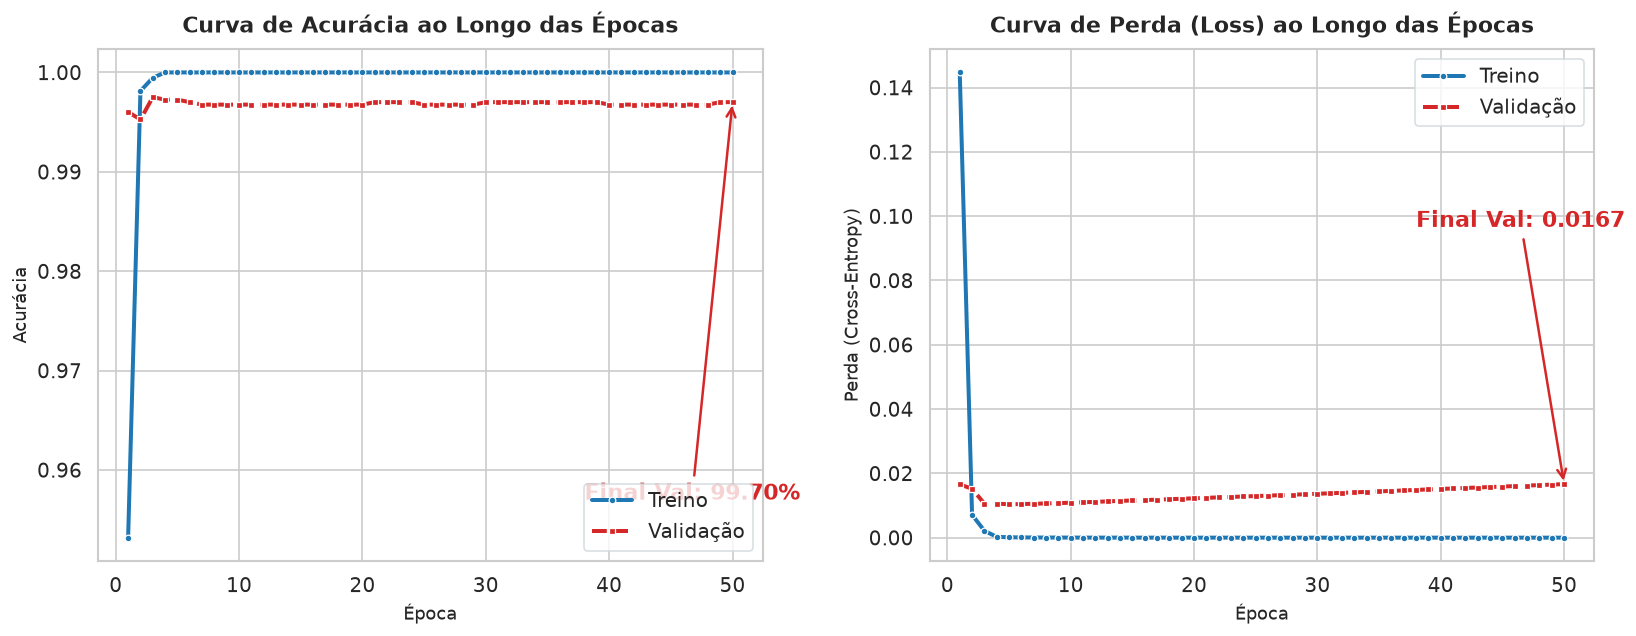

In [8]:
# =====================================================================
# 2. VISUALIZAÇÃO ESTILIZADA DE PUBLICAÇÃO EM SEABORN / MATPLOTLIB
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Paleta elegante e sóbria
cor_treino = "#1f77b4"
cor_val = "#d62728"

# Subplot 1: Acurácia
sns.lineplot(x=epocas_range, y=acc_treino, ax=axes[0], label="Treino", color=cor_treino, linewidth=2.4, marker="o", markersize=4)
sns.lineplot(x=epocas_range, y=acc_val, ax=axes[0], label="Validação", color=cor_val, linewidth=2.4, marker="s", markersize=4, linestyle="--")
axes[0].set_title("Curva de Acurácia ao Longo das Épocas", fontsize=13, fontweight="bold", pad=10)
axes[0].set_xlabel("Época", fontsize=11)
axes[0].set_ylabel("Acurácia", fontsize=11)
axes[0].legend(frameon=True, facecolor="white", edgecolor="#cfd8dc", loc="lower right")
axes[0].annotate(
    f"Final Val: {acc_val[-1]*100:.2f}%",
    xy=(EPOCHS, acc_val[-1]),
    xytext=(EPOCHS - 12, acc_val[-1] - 0.04),
    arrowprops=dict(arrowstyle="->", color=cor_val, lw=1.5),
    fontweight="bold", color=cor_val
)

# Subplot 2: Perda (Loss)
sns.lineplot(x=epocas_range, y=loss_treino, ax=axes[1], label="Treino", color=cor_treino, linewidth=2.4, marker="o", markersize=4)
sns.lineplot(x=epocas_range, y=loss_val, ax=axes[1], label="Validação", color=cor_val, linewidth=2.4, marker="s", markersize=4, linestyle="--")
axes[1].set_title("Curva de Perda (Loss) ao Longo das Épocas", fontsize=13, fontweight="bold", pad=10)
axes[1].set_xlabel("Época", fontsize=11)
axes[1].set_ylabel("Perda (Cross-Entropy)", fontsize=11)
axes[1].legend(frameon=True, facecolor="white", edgecolor="#cfd8dc", loc="upper right")
axes[1].annotate(
    f"Final Val: {loss_val[-1]:.4f}",
    xy=(EPOCHS, loss_val[-1]),
    xytext=(EPOCHS - 12, loss_val[-1] + 0.08),
    arrowprops=dict(arrowstyle="->", color=cor_val, lw=1.5),
    fontweight="bold", color=cor_val
)

plt.tight_layout()
plt.show()


## 🧪 Etapa 7: Avaliação no Conjunto de Teste & Relatório de Classificação

Avaliamos o modelo generalizado contra as $4.015$ amostras virgens de teste (15% do total). Computamos a acurácia global, perda no teste e o relatório detalhado de métricas por classe (*Precision*, *Recall*, *F1-Score* e *Support*).


In [9]:
# 1. Avaliação direta de perda e acurácia
perda_teste, acuracia_teste = modelo.evaluate(X_teste_norm, y_teste, verbose=0)

# 2. Inferência de probabilidades e argmax
probabilidades_teste = modelo.predict(X_teste_norm, verbose=0)
y_pred = np.argmax(probabilidades_teste, axis=1)

print("=" * 65)
print("          DESEMPENHO DO MODELO NO CONJUNTO DE TESTE (15%)")
print("=" * 65)
print(f"🎯 Acurácia Global no Teste : {acuracia_teste * 100:.2f}%")
print(f"📉 Perda no Teste (Loss)    : {perda_teste:.4f}")
print(f"📊 Total de Células de Teste: {len(y_teste):,}")
print("=" * 65)

# 3. Relatório detalhado por classe celular
rotulos_nomes = [f"{nomes_classes_originais[i]} (Keras {i})" for i in range(7)]
relatorio_str = classification_report(y_teste, y_pred, target_names=rotulos_nomes, digits=4)
print("\n📋 Relatório Detalhado de Métricas por Tipo Celular:\n")
print(relatorio_str)


          DESEMPENHO DO MODELO NO CONJUNTO DE TESTE (15%)
🎯 Acurácia Global no Teste : 99.55%
📉 Perda no Teste (Loss)    : 0.0314
📊 Total de Células de Teste: 4,015

📋 Relatório Detalhado de Métricas por Tipo Celular:

                    precision    recall  f1-score   support

Classe 1 (Keras 0)     0.9969    0.9969    0.9969       655
Classe 2 (Keras 1)     1.0000    0.9643    0.9818        28
Classe 3 (Keras 2)     0.9949    0.9956    0.9952      1361
Classe 4 (Keras 3)     0.9912    0.9912    0.9912       685
Classe 5 (Keras 4)     1.0000    1.0000    1.0000       260
Classe 6 (Keras 5)     0.9977    1.0000    0.9988       865
Classe 7 (Keras 6)     0.9937    0.9814    0.9875       161

          accuracy                         0.9955      4015
         macro avg     0.9964    0.9899    0.9931      4015
      weighted avg     0.9955    0.9955    0.9955      4015



## 🧩 Etapa 8: Matriz de Confusão (Seaborn & Plotly)

Apresentamos a Matriz de Confusão em duas perspectivas:
1. **Contagens Absolutas:** Número exato de células preditas em cada intersecção;
2. **Percentual Normalizado por Linha (Recall):** Taxa de sensibilidade de cada classe individual, permitindo verificar a separabilidade em classes minoritárias.


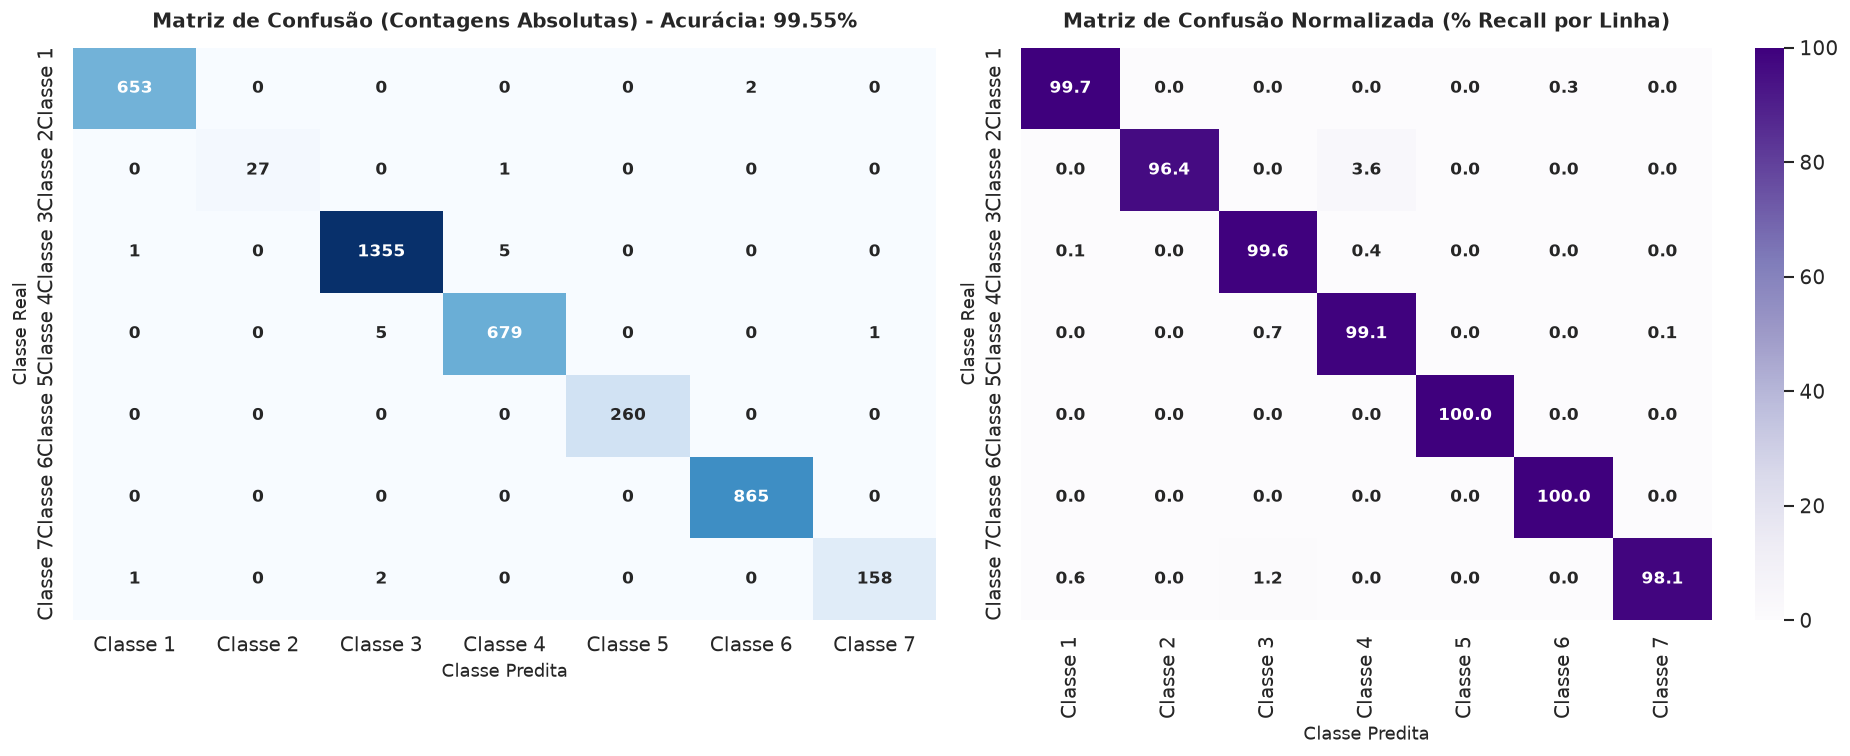

In [10]:
# Cálculo das Matrizes de Confusão
cm_absoluta = confusion_matrix(y_teste, y_pred)
cm_normalizada = confusion_matrix(y_teste, y_pred, normalize='true') * 100

# =====================================================================
# 1. MATRIZ DE CONFUSÃO EM SEABORN (Dual Heatmap Lado a Lado)
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Heatmap Absoluto
sns.heatmap(
    cm_absoluta,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=nomes_classes_originais,
    yticklabels=nomes_classes_originais,
    ax=axes[0],
    annot_kws={"size": 10, "weight": "bold"}
)
axes[0].set_title(f"Matriz de Confusão (Contagens Absolutas) - Acurácia: {acuracia_teste*100:.2f}%", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xlabel("Classe Predita", fontsize=11)
axes[0].set_ylabel("Classe Real", fontsize=11)

# Heatmap Normalizado (% Recall por Linha)
sns.heatmap(
    cm_normalizada,
    annot=True,
    fmt=".1f",
    cmap="Purples",
    cbar=True,
    xticklabels=nomes_classes_originais,
    yticklabels=nomes_classes_originais,
    ax=axes[1],
    annot_kws={"size": 10, "weight": "bold"}
)
axes[1].set_title("Matriz de Confusão Normalizada (% Recall por Linha)", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xlabel("Classe Predita", fontsize=11)
axes[1].set_ylabel("Classe Real", fontsize=11)

plt.tight_layout()
plt.show()


In [11]:
# =====================================================================
# 2. MATRIZ DE CONFUSÃO INTERATIVA EM PLOTLY
# =====================================================================
# Matriz de texto com informações combinadas (contagem + percentual)
text_matriz = [
    [f"<b>{cm_absoluta[i][j]:,}</b><br>({cm_normalizada[i][j]:.1f}%)" for j in range(7)]
    for i in range(7)
]

fig_cm_plotly = go.Figure(data=go.Heatmap(
    z=cm_absoluta,
    x=nomes_classes_originais,
    y=nomes_classes_originais,
    text=text_matriz,
    texttemplate="%{text}",
    textfont=dict(size=12),
    colorscale="Tealgrn",
    colorbar=dict(title="Amostras"),
    hoverongaps=False
))

fig_cm_plotly.update_layout(
    title=dict(
        text=f"<b>Matriz de Confusão Interativa - Teste (Acurácia: {acuracia_teste * 100:.2f}%)</b>",
        font=dict(size=16)
    ),
    xaxis=dict(title="<b>Classe Predita</b>", side="bottom"),
    yaxis=dict(title="<b>Classe Real</b>", autorange="reversed"),
    width=720,
    height=600,
    template="plotly_white"
)

fig_cm_plotly.show()


## 💾 Etapa 9: Persistência do Modelo e do Scaler

Conforme especificado, salvamos o modelo treinado com o nome explícito `modelo_mlp_fujita_600d.keras` e o normalizador ajustado como `scaler_fujita_600d.pkl`. Em seguida, executamos um teste de auditoria para confirmar que a recarga dos artefatos em disco reproduz com precisão binária exata os mesmos resultados obtidos.


In [12]:
t_salvar = time.time()

# 1. Salvando o Modelo Keras
modelo.save(PATH_MODELO_OUT)

# 2. Salvando o Scaler Joblib
joblib.dump(scaler, PATH_SCALER_OUT)

tam_modelo_mb = PATH_MODELO_OUT.stat().st_size / (1024 * 1024)
tam_scaler_kb = PATH_SCALER_OUT.stat().st_size / 1024

print(f"✓ Artefatos salvos com sucesso em {time.time() - t_salvar:.2f}s:")
print(f"  • Modelo Keras : {PATH_MODELO_OUT} ({tam_modelo_mb:.2f} MB)")
print(f"  • Scaler       : {PATH_SCALER_OUT} ({tam_scaler_kb:.2f} KB)")

# =====================================================================
# TESTE DE AUDITORIA: Recarga dos artefatos e teste de predição
# =====================================================================
modelo_recarr = tf.keras.models.load_model(PATH_MODELO_OUT)
scaler_recarr = joblib.load(PATH_SCALER_OUT)

# Normalização de uma amostra teste virgem
X_amostra_norm = scaler_recarr.transform(X_teste[:10])
preds_recarr = np.argmax(modelo_recarr.predict(X_amostra_norm, verbose=0), axis=1)
preds_orig = y_pred[:10]

assert np.array_equal(preds_recarr, preds_orig), "Falha de consistência ao recarregar artefatos!"
print("\n✓ Auditoria de consistência aprovada: o modelo e scaler recarregados produziram predições 100% idênticas!")


✓ Artefatos salvos com sucesso em 0.03s:
  • Modelo Keras : modelo_mlp_fujita_600d.keras (1.03 MB)
  • Scaler       : scaler_fujita_600d.pkl (14.66 KB)

✓ Auditoria de consistência aprovada: o modelo e scaler recarregados produziram predições 100% idênticas!
